# 확장 연구 (2026-11-03): 비중 × 리밸런싱 주기 × 지표 × 요인 순서 × 거래비용

우동호 외(2023) 유니버스에서 마법공식의 두 요인(가치·질)은 그대로 두고, **지표**, **요인을 쓰는 순서**, **비중**, **리밸런싱 주기**, **거래비용**을 바꿔 돌린다.
결과표는 전략 × 비중 × 주기 × 비용 × 기간 한 장(`연구/결과/확장연구_20261103.csv`)이고, 아래에서 그 표를 잘라 보인다.

줄임말: EW(동일가중), VW(시가총액가중), MDD(최대 낙폭), IR(정보비율: 자체 벤치마크 대비), CAPM·FF3·Carhart(요인모형), NW(뉴이-웨스트 t), TR(배당 포함 수정주가), EV(기업가치 = 시가총액 + 부채총계 − 현금).

| 항목 | 설정 | 근거 |
|---|---|---|
| 유니버스 | 코스피 + 코스닥, 보통주, 금융업·투자기구 제외, 12월 결산, 기준일 거래정지 제외 | 우동호 외(2023) 3.1절 p.512 (`포.우동호2023`의 제외 목록과 같음) |
| 기간 | 1990-04 첫 리밸런싱 ~ 2026-09 | 데이터 범위(1988~), 4월 리밸런싱(우동호) |
| 기준일 | 매달 첫 거래일 | 우동호 p.512–513 |
| 재무 시점 | 실적보고서발표일 다음 거래일, 발표일이 없으면 결산일 + 150일 | 02 노트북 발표 지연 통계(150일). 월·분기 리밸런싱이라 '결산 후 3개월'(우동호 본문)은 발표 전 재무를 쓸 수 있어 안 씀 |
| 가격 | 배당 포함 수정주가(TR, S410007700) | 실제 투자자가 받는 수익. 01 노트북(우동호 재현)은 원문대로 배당 미포함 |
| 종목 수 | 상위 30 | 우동호 p.512 |
| 비중 | 동일·시총·시총상한(10%)·위험균형(직전 1년 변동성 역수)·최소분산(직전 36개월, Ledoit-Wolf) | README '비중'. 상한 10%와 36개월은 근거 없음 |
| 리밸런싱 주기 | 1·3·6·12개월 | 지시 |
| 매매 | 비중이 바뀐 만큼만 사고 판다(`전량교체=False`) | 우동호 원문은 1년마다 전량교체. 월 리밸런싱에 전량교체를 쓰면 겹치는 종목도 매달 다 팔고 사게 되어 실제 매매와 다름 |
| 거래비용 | 기본 = 수수료 0.015%, 거래세 0.25%(매도), 슬리피지 0.5%(매수·매도마다). 민감도 0배·1배·2배 | 우동호 p.512 |
| 주 벤치마크 | 유니버스 전체(거른 뒤 모든 종목) 시가총액 가중, 매달 다시 맞춤, 비용 0 | 지시. 정보비율(IR)은 이것 대비 |
| 참고 벤치마크 | 코스피(I.001)·코스피TR(I.030)·코스닥(I.201)·코스닥TR(I.273)·KRX TMI(I.578, 2010-04-01부터) | X01, R12 xlsx. KRX TMI가 배당 포함인지는 확인 안 함 |
| 알파 | 시장 = 코스피(I.001), SMB·HML·MOM = DataGuide 요인지수, RF = 콜금리(E11.02.003.001) | README '요인'·'무위험이자율'. **포트폴리오는 배당 포함(TR)인데 시장 요인은 배당 미포함 가격지수라 알파가 배당수익률만큼 높게 나온다**(코스피TR I.030은 2011-01-03부터만 있어 전체 기간에 못 씀). 요인 첫 값은 1990-07이라 CAPM과 FF3·Carhart의 첫 달이 다를 수 있다(감사 #6·#14) |
| 근거 없는 값 | 단계별 남길 비율 0.5, 시총상한 0.1, 최소분산 36개월, 2년 넘은 재무 안 씀, 1990~2003에도 원문(2004~2022) 거래비용 | 근거 없음(감사 #7). 결과는 이 값들에 달려 있을 수 있다 |
| 보유 종목 수 | 위험균형은 직전 12개월 상장·변동성 > 0인 종목만, 최소분산은 36개월 수익률이 다 있는 종목만 비중을 받는다 | 그래서 비중 방식끼리 종목 집합이 조금 다르다. 리밸런싱마다 실제 보유 수는 `기록`의 `보유수:전략:비중:상위30` 칸(7절, 감사 #2) |


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import time
import pandas as pd
import 데이터읽기 as 읽기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
print("데이터:", 읽기.DATA)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611


## 1. 지표와 근거
요인마다 지표 4개. 기준(마법공식)은 EY와 ROC다. 근거 칸의 쪽수는 원문 PDF에서 확인한 것이고, 원문을 확인하지 못한 것은 '확인 안 함'이라고 적었다.
비율 지표는 수익률 꼴(이익/가격)로 높을수록 좋다(`공통/지표.py` 맨 위 설명).

In [2]:
가치 = {"EY": "EBIT / EV. 우동호 외(2023) p.512, 그린블라트(2005)",
        "EBITDA_EV": "EBITDA / EV. NH 밸류(2018) p.14 'EV/EBITDA'",
        "EP": "지배순이익 / 시가총액. NH 밸류(2018) p.14 'P/E'",
        "영업이익_EV": "영업이익(발표기준) / EV. 인수자 배수(Acquirer's Multiple): 우동호 외(2023) 참고문헌의 Arif·Sumirat(2022), 칼라일 책. 두 원문 모두 확인 안 함"}
질 = {"ROC": "EBIT / (순운전자본 + 순고정자산). 우동호 외(2023) p.512",
      "GPA": "매출총이익 / 자산총계. 우동호 외(2023) p.513, Novy-Marx(2013)",
      "ROE": "지배순이익 / 지배자본. NH 퀄리티(2018) p.18",
      "영업CF자산": "영업활동현금흐름 / 자산총계. 근거 논문·리포트 원문 확인 안 함(가진 자료에서 못 찾음)"}
남길비율 = 0.5  # 단계별: 앞 요인으로 상위 50%를 남기고 뒤 요인으로 30종목. 근거 없음(예전 팩터순서 노트북에서 쓴 값)
pd.concat({"가치": pd.Series(가치), "질": pd.Series(질)}).rename("근거").to_frame()

근거
가치 EY                 EBIT / EV. 우동호 외(2023) p.512, 그린블라트(2005)
   EBITDA_EV          EBITDA / EV. NH 밸류(2018) p.14 'EV/EBITDA'
   EP                      지배순이익 / 시가총액. NH 밸류(2018) p.14 'P/E'
   영업이익_EV    영업이익(발표기준) / EV. 인수자 배수(Acquirer's Multiple): ...
질  ROC                EBIT / (순운전자본 + 순고정자산). 우동호 외(2023) p.512
   GPA         매출총이익 / 자산총계. 우동호 외(2023) p.513, Novy-Marx(2013)
   ROE                          지배순이익 / 지배자본. NH 퀄리티(2018) p.18
   영업CF자산     영업활동현금흐름 / 자산총계. 근거 논문·리포트 원문 확인 안 함(가진 자료에서 못...

## 2. 전략 목록과 설정
전략 = 가치 지표 × 질 지표 × 순서(순위합산 / 가치 먼저 → 질 / 질 먼저 → 가치). 지표에 드는 파일이 아직 없으면 그 지표가 든 전략은 빼고 이름을 출력한다(파일 오면 다시 실행).

In [3]:
필요 = {"EY": ["M000907001", "M000906020", "M000902001", "M000901030"], "EBITDA_EV": ["M000701032"], "EP": ["M000908004"],
        "영업이익_EV": ["M000906002"], "ROC": ["M000901002", "M000902003", "M000901001", "M000901024"], "GPA": ["M000904007"],
        "ROE": ["M000908004", "M000903003"], "영업CF자산": ["M000909001"]}
없음 = {m for m, items in 필요.items() if not all(읽기.있음(i) for i in items)}
print("파일이 없어 뺀 지표(파일 오면 다시 실행):", sorted(없음) or "없음")
전략들 = {}
for v in 가치:
    for q in 질:
        if {v, q} & 없음:
            continue
        전략들[f"{v}+{q} 순위합산"] = dict(지표=[(v, "높게"), (q, "높게")], 합산="순위합산")
        전략들[f"{v}→{q}"] = dict(지표=[(v, "높게", 남길비율), (q, "높게", 1.0)], 합산="단계별")
        전략들[f"{q}→{v}"] = dict(지표=[(q, "높게", 남길비율), (v, "높게", 1.0)], 합산="단계별")
기간 = ("1990-04", "2026-09")
설정 = {**포.기본설정, "이름": "확장연구", "시장": ["KS", "KQ"], "기간": 기간, "기준일": "첫거래일",
        "재무시점": ("발표일", 150), "제외": 포.우동호2023["제외"], "가격": 읽기.TR, "고르기": ("상위N", 30),
        "비중": ["동일", "시총", "시총상한", "위험균형", "최소분산"], "비중상한": 0.1, "전량교체": False,
        "거래비용": dict(수수료=0.00015, 거래세=0.0025, 슬리피지=0.005), "무위험": "E11.02.003.001", "시장지수": "I.001", "전략들": 전략들}
주기들 = [1, 3, 6, 12]
비용배수 = {"비용0": 0, "비용기본": 1, "비용2배": 2}
print(f"전략 {len(전략들)}개 × 비중 {len(설정['비중'])} × 주기 {len(주기들)} × 비용 {len(비용배수)}")
pd.Series({k: str(v) for k, v in 설정.items() if k != "전략들"}).to_frame("설정")

파일이 없어 뺀 지표(파일 오면 다시 실행): 없음
전략 48개 × 비중 5 × 주기 4 × 비용 3


,설정
시장,"['KS', 'KQ']"
가격,S410007700
기간,"('1990-04', '2026-09')"
기준일,첫거래일
리밸런싱,12
재무시점,"('발표일', 150)"
제외,"['보통주', '금융업', '투자기구', ('결산월', {'월': 12}), '거래..."
지표,"[('ROC', '높게'), ('EY', '높게')]"
합산,순위합산
고르기,"('상위N', 30)"


## 3. 실행
주기마다 `포.실행`을 한 번 부른다. 기준일마다 거르기와 지표 계산은 한 번만 하고, 모든 전략이 같은 거른 종목에서 고른다. 비용 0배·2배는 같은 보유 비중으로 수익률만 다시 계산한다(`포.보유`).

In [4]:
결과, 수익 = {}, {}
for k in 주기들:
    t0 = time.time()
    o = 결과[k] = 포.실행({**설정, "리밸런싱": k})
    for 비용, x in 비용배수.items():
        c = {n: v * x for n, v in 설정["거래비용"].items()}
        for key, W in o["보유"].items():
            if key[0] != "유니버스":
                수익[(key[0], key[1], k, 비용)] = o["수익률"][key] if x == 1 else 포.보유(o["종목수익률"], W, c, 설정["전량교체"])
    print(f"{k}개월: 리밸런싱 {len(o['기록'])}회, {time.time() - t0:.0f}초")
수익 = pd.DataFrame(수익).rename_axis(columns=["전략", "비중", "주기", "비용"])
grid = 포.기준일(설정)
벤치 = pd.DataFrame({"유니버스(시총가중)": 포.보유(결과[1]["종목수익률"], 결과[1]["보유"][("유니버스", "시총", "전체")], dict(수수료=0, 거래세=0, 슬리피지=0))})
지수 = {"코스피": 읽기.지수()["I.001"], "코스피TR": 읽기.지수()["I.030"], "코스닥": 읽기.지수()["I.201"], "코스닥TR": 읽기.지수()["I.273"], "KRX TMI": 읽기.KRX지수()["I.578"]}
for n, x in 지수.items():
    벤치[n] = x.reindex(grid).pct_change(fill_method=None)
F = 평가.요인(grid, 설정)
F주 = F.assign(시장=벤치["유니버스(시총가중)"])  # 정보비율은 유니버스 벤치마크 대비. 알파의 MKT는 코스피 − RF 그대로
수익.shape

1개월: 리밸런싱 437회, 1669초


3개월: 리밸런싱 146회, 577초


6개월: 리밸런싱 73회, 298초


12개월: 리밸런싱 37회, 150초


(437, 2880)

## 4. 결과표: 전략 × 비중 × 주기 × 비용 × 기간
기간은 `평가.구간들`(전체, 1990-04~2004-03, 2004-04~2017-03, 2017-04~)과 '공통'(모든 전략·비중·주기에 수익률이 생긴 첫 보유 월부터 끝까지)이다. 최소분산·위험균형은 과거 수익률이 쌓인 뒤에 시작하므로, 비중 방식끼리 비교는 '공통' 기간으로 본다(감사 M3). 24개월보다 짧은 칸은 뺀다. 정보비율은 유니버스 시가총액 가중 벤치마크 대비다.
벤치마크 줄의 비중 칸은 '-', 주기 칸은 0이다.
칸: 개월·누적·연환산(기하)·표준편차(연, 월 표준편차 × √12)·벤치 대비 연환산(같은 달들의 유니버스 벤치마크 연환산과 차이)·샤프·MDD·정보비율(유니버스 대비)·CAPM·FF3·Carhart α(월)와 Carhart t(NW)·adj R²·회전율(리밸런싱당 평균 한쪽, 전 기간). 타겟 페이퍼(우동호 표 2~7) 지표는 누적·MDD·표준편차·샤프·정보비율·젠센(CAPM)·3요인·4요인 α이다(`공통/평가.py` 맨 위).

In [5]:
칸 = ["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "정보비율", "CAPM α(월)", "FF3 α(월)", "Carhart α(월)", "Carhart t(NW)", "Carhart adj R²"]
공통 = str((수익.apply(lambda r: r.first_valid_index()).max() - pd.Timedelta(days=15)).to_period("M"))  # 평가.구간과 같은 보유 월 계산
기간들 = {**평가.구간들, "공통": (공통, None)}
print("공통 기간 시작(보유 월):", 공통)
처음뺌 = lambda s: s.iloc[s.gt(0).to_numpy().argmax() + 1:].mean()  # 처음 종목을 산 리밸런싱(=1)과 그 전 빈 비중(=0)을 뺀 평균(감사 L4)
회전 = pd.concat({k: o["회전율"].drop(columns=[("유니버스", "시총", "전체")]).apply(처음뺌) for k, o in 결과.items()}, names=["주기"])  # 리밸런싱당 평균 한쪽 회전율
u = 벤치["유니버스(시총가중)"]
rows = {}
for key, r in list(수익.items()) + [(("벤치:" + n, "-", 0, "비용0"), r) for n, r in 벤치.items()]:
    for g, (a, b) in 기간들.items():
        x = 평가.구간(r.dropna(), a, b)
        if len(x) >= 24:
            o = {k: v for k, v in 평가.성과(x, F주).items() if k in 칸}
            o["벤치 대비 연환산"] = o["연환산"] - ((1 + u.reindex(x.index)).prod() ** (12 / len(x)) - 1)  # 같은 달들의 유니버스 벤치마크 연환산과 차이
            o["회전율(전 기간)"] = 회전.get((key[2], key[0], key[1], "상위30"), float("nan"))  # 리밸런싱당 평균 한쪽 회전율(기간 나누지 않음)
            rows[(*key, g)] = o
표 = pd.DataFrame(rows).T[칸[:4] + ["벤치 대비 연환산"] + 칸[4:] + ["회전율(전 기간)"]].rename_axis(["전략", "비중", "주기", "비용", "기간"])
표.to_csv(Path.cwd() / "결과" / "확장연구_20261103.csv", encoding="utf-8-sig")
pd.to_pickle(dict(수익=수익, 벤치=벤치, F=F, F주=F주, 표=표, 회전=회전, 기록={k: o["기록"] for k, o in 결과.items()},
                  설정={k: v for k, v in 설정.items() if k != "전략들"}, 전략들=전략들),
             Path.cwd() / "결과" / "확장연구_20261103.pkl")  # 결과요약 노트북이 읽음(결과_월수익률/에 두면 평가.요약이 읽으려다 형식이 달라 멈춤)
print("저장:", len(표), "줄")
표.loc[[i for i in 표.index if i[0].startswith("벤치:") and i[4] == "전체"]]

공통 기간 시작(보유 월): 1993-04


저장: 14427 줄


,,,,,개월,누적,연환산,표준편차(연),벤치 대비 연환산,샤프,MDD,정보비율,CAPM α(월),FF3 α(월),Carhart α(월),Carhart t(NW),Carhart adj R²,회전율(전 기간)
전략,비중,주기,비용,기간,,,,,,,,,,,,,,
벤치:유니버스(시총가중),-,0,비용0,전체,437.0000,18.6072,0.0851,0.2724,0.0000,0.2231,-0.6101,NaN,0.0021,0.0035,0.0032,5.1880,0.9739,NaN
벤치:코스피,-,0,비용0,전체,437.0000,7.1545,0.0593,0.2697,-0.0258,0.1327,-0.7243,-0.4442,0.0000,0.0000,0.0000,8.4753,1.0000,NaN
벤치:코스피TR,-,0,비용0,전체,188.0000,3.3359,0.0982,0.2186,0.0030,0.4375,-0.3123,0.0729,0.0015,0.0015,0.0015,7.4199,0.9971,NaN
벤치:코스닥,-,0,비용0,전체,362.0000,-0.1788,-0.0065,0.3253,-0.0996,0.0151,-0.8904,-0.3721,-0.0040,0.0005,0.0005,0.2081,0.7287,NaN
벤치:코스닥TR,-,0,비용0,전체,188.0000,0.7567,0.0366,0.2229,-0.0585,0.1771,-0.3922,-0.3326,-0.0011,0.0014,0.0018,0.9923,0.8275,NaN
벤치:KRX TMI,-,0,비용0,전체,197.0000,3.2605,0.0923,0.2187,-0.0118,0.4132,-0.3349,-0.4177,0.0003,0.0006,0.0006,1.4067,0.9941,NaN


## 5. 잘라 보기
### 5-1. 기준(EY+ROC 순위합산 = 마법공식)의 비중 × 주기 (전체 기간, 기본 비용. 비중 방식마다 시작 달이 달라 비중끼리 비교는 5-5의 '공통' 기간으로)

In [6]:
전체 = 표.xs("전체", level="기간")
기본 = 전체.xs("비용기본", level="비용")
display(기본.loc["EY+ROC 순위합산"]["샤프"].unstack("주기").style.set_caption("샤프"))
기본.loc["EY+ROC 순위합산"][["누적", "연환산", "MDD", "정보비율", "Carhart α(월)", "Carhart t(NW)"]]

주기,1,3,6,12
비중,,,,
동일,0.416418,0.384202,0.316575,0.294822
시총,0.282428,0.244443,0.184826,0.186704
시총상한,0.183347,0.159233,0.145188,0.149848
위험균형,0.400653,0.376821,0.397403,0.371475
최소분산,0.310799,0.335100,0.400784,0.228517


,,누적,연환산,MDD,정보비율,Carhart α(월),Carhart t(NW)
비중,주기,,,,,,
동일,1,178.9104,0.1533,-0.5736,0.2675,0.0099,2.4050
시총,1,33.7192,0.1023,-0.6974,0.1283,0.0058,1.6571
시총상한,1,11.6535,0.0722,-0.5804,-0.0428,0.0019,0.7221
위험균형,1,116.6901,0.1430,-0.5674,0.2179,0.0074,2.0050
최소분산,1,26.7501,0.1037,-0.6496,0.0664,0.0018,0.7443
동일,3,121.8092,0.1412,-0.5627,0.2334,0.0092,2.1512
시총,3,20.5830,0.0880,-0.6942,0.0834,0.0049,1.3560
시총상한,3,8.6887,0.0643,-0.6186,-0.0695,0.0016,0.5621
위험균형,3,90.1433,0.1349,-0.5558,0.1881,0.0069,1.8473


### 5-2. 모든 전략: 동일가중·12개월·기본 비용, 전체 기간 (샤프 순)

In [7]:
기본.xs(("동일", 12), level=["비중", "주기"]).sort_values("샤프", ascending=False)

,개월,누적,연환산,표준편차(연),벤치 대비 연환산,샤프,MDD,정보비율,CAPM α(월),FF3 α(월),Carhart α(월),Carhart t(NW),Carhart adj R²,회전율(전 기간)
전략,,,,,,,,,,,,,,
GPA→EP,437.0000,1730.6839,0.2272,0.4014,0.1421,0.5394,-0.6574,0.4483,0.0159,0.0168,0.0169,2.4220,0.5095,0.7960
ROC→EBITDA_EV,437.0000,877.9528,0.2046,0.3353,0.1194,0.5345,-0.5117,0.4210,0.0130,0.0147,0.0144,2.8773,0.5743,0.6831
영업CF자산→EBITDA_EV,437.0000,1033.2817,0.2100,0.3542,0.1248,0.5341,-0.5757,0.4479,0.0136,0.0156,0.0151,2.6714,0.5593,0.6954
ROE→EP,437.0000,1071.0250,0.2112,0.3788,0.1260,0.5292,-0.6545,0.4395,0.0145,0.0132,0.0129,2.6534,0.5903,0.8626
ROE→EBITDA_EV,437.0000,959.1090,0.2075,0.3634,0.1224,0.5210,-0.6007,0.4249,0.0137,0.0157,0.0152,2.6111,0.5436,0.6917
GPA→EBITDA_EV,437.0000,949.0601,0.2072,0.3660,0.1220,0.5157,-0.4876,0.4148,0.0137,0.0161,0.0158,2.5246,0.5312,0.6889
영업CF자산→EP,437.0000,1016.1490,0.2094,0.3865,0.1243,0.5111,-0.6707,0.4045,0.0144,0.0151,0.0148,2.1508,0.4801,0.8312
EP+영업CF자산 순위합산,437.0000,1068.1670,0.2111,0.3905,0.1259,0.5044,-0.5716,0.4051,0.0143,0.0162,0.0159,2.1914,0.4782,0.8500
GPA→영업이익_EV,437.0000,592.6157,0.1917,0.3617,0.1065,0.4866,-0.6053,0.3804,0.0126,0.0145,0.0142,2.4978,0.5727,0.6897


### 5-3. 지표 바꾸기: 순위합산, 동일가중·12개월·기본 비용 — 가치 × 질 샤프 (전체 기간)

In [8]:
s = 기본.xs(("동일", 12), level=["비중", "주기"])["샤프"]
s = s[s.index.str.endswith(" 순위합산")]
s.index = pd.MultiIndex.from_tuples([tuple(i.removesuffix(" 순위합산").split("+")) for i in s.index], names=["가치", "질"])
s.unstack("질")

질,GPA,ROC,ROE,영업CF자산
가치,,,,
EBITDA_EV,0.4448,0.3570,0.3892,0.4386
EP,0.4548,0.3224,0.4216,0.5044
EY,0.4211,0.2948,0.3168,0.4523
영업이익_EV,0.3810,0.3225,0.3565,0.4292


### 5-4. 요인 순서: 순위합산 vs 가치 먼저 vs 질 먼저 (동일가중·12개월·기본 비용, 전체 기간 샤프)

In [9]:
순서표 = pd.DataFrame({(v, q): {"순위합산": s[(v, q)], "가치→질": 기본.loc[(f"{v}→{q}", "동일", 12), "샤프"], "질→가치": 기본.loc[(f"{q}→{v}", "동일", 12), "샤프"]}
                    for v, q in s.index}).T.rename_axis(["가치", "질"])
display(순서표)
순서표.idxmax(axis=1).value_counts().rename("샤프가 가장 높은 순서(조합 수)")

순위합산   가치→질   질→가치
가치        질                          
EY        ROC    0.2948 0.1463 0.4164
          GPA    0.4211 0.3854 0.4803
          ROE    0.3168 0.1888 0.4458
          영업CF자산 0.4523 0.3163 0.4436
EBITDA_EV ROC    0.3570 0.2740 0.5345
          GPA    0.4448 0.3813 0.5157
          ROE    0.3892 0.2466 0.5210
          영업CF자산 0.4386 0.3082 0.5341
EP        ROC    0.3224 0.1718 0.4824
          GPA    0.4548 0.3910 0.5394
          ROE    0.4216 0.1792 0.5292
          영업CF자산 0.5044 0.3634 0.5111
영업이익_EV   ROC    0.3225 0.2777 0.4417
          GPA    0.3810 0.3641 0.4866
          ROE    0.3565 0.2494 0.4502
          영업CF자산 0.4292 0.3272 0.4606

질→가치    15
순위합산     1
Name: 샤프가 가장 높은 순서(조합 수), dtype: int64

### 5-5. 비중 방식별·주기별: 모든 전략의 샤프 중앙값 ('공통' 기간 = 모든 비중 방식이 같은 달부터, 기본 비용)

In [10]:
공통표 = 표.xs(("공통", "비용기본"), level=["기간", "비용"])
print("공통 기간 시작(보유 월):", 공통)
공통표["샤프"].drop(index=[i for i in 공통표.index if i[0].startswith("벤치:")]).groupby(["비중", "주기"]).median().unstack("주기")

공통 기간 시작(보유 월): 1993-04


주기,1,3,6,12
비중,,,,
동일,0.6038,0.5723,0.4455,0.4141
시총,0.3711,0.3479,0.2874,0.3785
시총상한,0.3764,0.3682,0.2833,0.3353
위험균형,0.5569,0.5209,0.4520,0.4499
최소분산,0.4634,0.4134,0.4229,0.3844


### 5-6. 거래비용 민감도: 비용 0·기본·2배의 연환산 수익률 중앙값 (전 전략, 전체 기간)과 회전율

In [11]:
display(전체["연환산"].drop(index=[i for i in 전체.index if i[0].startswith("벤치:")]).groupby(["주기", "비용"]).median().unstack("비용")[list(비용배수)])
회전.groupby(level=[0, 2]).median().unstack(0).rename_axis(index="비중", columns="주기").style.set_caption("리밸런싱당 한쪽 회전율 중앙값(첫 매수 뺌, 전 전략)").format(precision=3)

비용,비용0,비용기본,비용2배
주기,,,
1,0.1902,0.1558,0.1205
3,0.1736,0.1509,0.1287
6,0.1496,0.1329,0.1175
12,0.1461,0.1341,0.1228


주기,1,3,6,12
비중,,,,
동일,0.191,0.372,0.559,0.763
시총,0.197,0.360,0.538,0.727
시총상한,0.187,0.362,0.543,0.729
위험균형,0.194,0.378,0.563,0.778
최소분산,0.238,0.426,0.617,0.811


### 5-7. 기간별: 기준 전략(EY+ROC 순위합산, 동일가중, 12개월, 기본 비용)과 벤치마크

In [12]:
pd.concat({"기준 전략": 표.xs(("EY+ROC 순위합산", "동일", 12, "비용기본"), level=[0, 1, 2, 3]),
           **{n: 표.xs(("벤치:" + n, "-", 0, "비용0"), level=[0, 1, 2, 3]) for n in 벤치}}, names=["줄"])

개월      누적     연환산  표준편차(연)  벤치 대비 연환산      샤프     MDD    정보비율  CAPM α(월)  FF3 α(월)  Carhart α(월)  Carhart t(NW)  Carhart adj R²  회전율(전 기간)
줄          기간                                                                                                                                                               
기준 전략      전체              437.0000 43.3326  0.1097   0.3334     0.0246  0.2948 -0.7191  0.1337     0.0062    0.0076        0.0072         1.8668          0.6613     0.8131
           1990-04~2004-03 168.0000  5.2215  0.1395   0.4273     0.0958  0.2401 -0.7191  0.3061     0.0113    0.0128        0.0123         1.8252          0.7025     0.8131
           2004-04~2017-03 156.0000  5.3376  0.1526   0.2696     0.0619  0.5552 -0.5779  0.4050     0.0076    0.0027        0.0032         0.7545          0.6832     0.8131
           2017-04~        113.0000  0.1243  0.0125   0.2416    -0.1291  0.0868 -0.5510 -0.5368    -0.0039    0.0008        0.0004         0.1589          0.7020     0.8131
           공통              401.0000 23.5689  0.1005   0.3323     0.0031  0.2951 -0.7191  0.0647     0.0050    0.0070        0.0069         1.7334          0.6605     0.8131
유니버스(시총가중) 전체              437.0000 18.6072  0.0851   0.2724     0.0000  0.2231 -0.6101     NaN     0.0021    0.0035        0.0032         5.1880          0.9739        NaN
           1990-04~2004-03 168.0000  0.8206  0.0437   0.3370     0.0000 -0.0296 -0.6101     NaN     0.0033    0.0044        0.0042         2.9319          0.9651        NaN
           2004-04~2017-03 156.0000  2.0931  0.0907   0.1916     0.0000  0.3951 -0.4794     NaN     0.0016    0.0023        0.0021         3.5667          0.9833        NaN
           2017-04~        113.0000  2.4817  0.1417   0.2614     0.0000  0.5587 -0.3147     NaN     0.0009    0.0023        0.0023         4.6664          0.9921        NaN
           공통              401.0000 21.3522  0.0974   0.2705     0.0000  0.2967 -0.6101     NaN     0.0021    0.0036        0.0031         5.1668          0.9780        NaN
코스피        전체              437.0000  7.1545  0.0593   0.2697    -0.0258  0.1327 -0.7243 -0.4442     0.0000    0.0000        0.0000         8.4753          1.0000        NaN
           1990-04~2004-03 168.0000  0.0530  0.0037   0.3324    -0.0400 -0.1521 -0.7243 -0.5013    -0.0000    0.0000       -0.0000        -5.6712          1.0000        NaN
           2004-04~2017-03 156.0000  1.4554  0.0715   0.1924    -0.0192  0.3015 -0.5062 -0.5983     0.0000    0.0000        0.0000         2.9528          1.0000        NaN
           2017-04~        113.0000  2.1538  0.1297   0.2583    -0.0119  0.5203 -0.3438 -0.3345     0.0000   -0.0000        0.0000         1.7952          1.0000        NaN
           공통              401.0000  9.2700  0.0722   0.2673    -0.0252  0.2088 -0.7243 -0.4482     0.0000   -0.0000        0.0000         8.1490          1.0000        NaN
코스피TR      전체              188.0000  3.3359  0.0982   0.2186     0.0030  0.4375 -0.3123  0.0729     0.0015    0.0015        0.0015         7.4199          0.9971        NaN
           2004-04~2017-03  75.0000  0.1407  0.0213   0.1374    -0.0073  0.0525 -0.2334 -0.3219     0.0011    0.0010        0.0012         3.1799          0.9930        NaN
           2017-04~        113.0000  2.8012  0.1523   0.2582     0.0107  0.5980 -0.3123  0.2535     0.0017    0.0017        0.0017         6.7312          0.9979        NaN
           공통              188.0000  3.3359  0.0982   0.2186     0.0030  0.4375 -0.3123  0.0729     0.0015    0.0015        0.0015         7.4199          0.9971        NaN
코스닥        전체              362.0000 -0.1788 -0.0065   0.3253    -0.0996  0.0151 -0.8904 -0.3721    -0.0040    0.0005        0.0005         0.2081          0.7287        NaN
           1990-04~2004-03  93.0000 -0.5610 -0.1008   0.4894    -0.1413 -0.1527 -0.8639 -0.3147    -0.0063   -0.0032       -0.0036        -0.4469          0.6280        NaN
           2004-04~2017-03 156.0000  0.4317  0.0280   

### 5-8. 누적 그림: 기준 전략(비중별, 12개월, 기본 비용)과 벤치마크

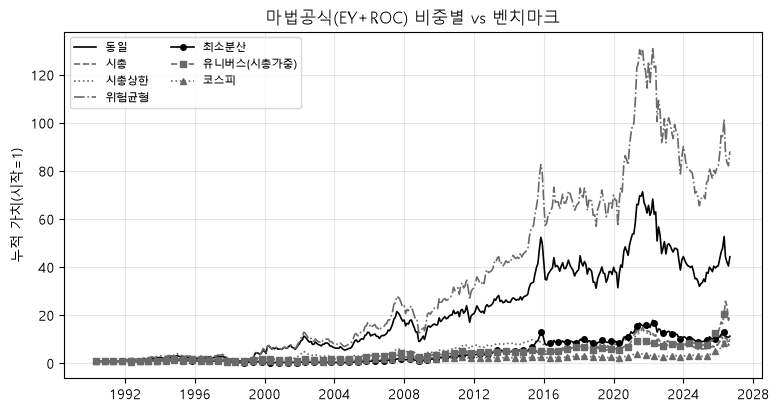

In [13]:
그림 = 수익.xs(("EY+ROC 순위합산", 12, "비용기본"), axis=1, level=[0, 2, 3])
평가.누적그림(pd.concat([그림, 벤치[["유니버스(시총가중)", "코스피"]]], axis=1).dropna(how="all"), "마법공식(EY+ROC) 비중별 vs 벤치마크");

## 6. 리포트용 표·그림 (`결과_전략수익률/`)
기준 = 마법공식(EY+ROC 순위합산), 동일가중, 12개월, 기본 비용. 비교마다 **한 가지 조건만** 바꾼 성과표(csv)와 누적 그림(png)을 저장한다. 벤치마크 줄(유니버스 시총가중·코스피)도 같은 기간으로 함께 둔다.
| 파일 | 바꾼 것 | 기간 |
|---|---|---|
| `1_비중` | 동일·시총·시총상한·위험균형·최소분산 | 공통(모든 비중이 수익률을 내는 첫 달부터) |
| `2_주기` | 1·3·6·12개월 | 전체 |
| `3_지표` | 가치 지표 4 × 질 지표 4 (순위합산) — 그림은 기준에서 지표 하나만 바꾼 7개 | 전체 |
| `4_순서` | 순위합산 / 가치 먼저 → 질 / 질 먼저 → 가치 | 전체 |
| `5_비용` | 비용 0·기본·2배 × 주기 1·12개월 | 전체 |
| `6_기간` | 1990-04~2004-03 / 2004-04~2017-03 / 2017-04~ | 기간별 |

저장: ['1_비중.csv', '1_비중.png', '2_주기.csv', '2_주기.png', '3_지표.csv', '3_지표.png', '4_순서.csv', '4_순서.png', '5_비용.csv', '5_비용.png', '6_기간.csv']


개월    연환산  표준편차(연)     샤프     MDD  회전율(전 기간)  벤치 대비 연환산    정보비율  Carhart α(월)  Carhart t(NW)
비교   전략            비중   주기 비용   기간                                                                                                   
1_비중 EY+ROC 순위합산   동일   12 비용기본 공통 401.0000 0.1005   0.3323 0.2951 -0.7191     0.8131     0.0031  0.0647        0.0069         1.7334
                   시총   12 비용기본 공통 401.0000 0.0638   0.3691 0.2091 -0.7309     0.7564    -0.0336 -0.0116        0.0030         0.8513
                   시총상한 12 비용기본 공통 401.0000 0.0573   0.2986 0.1685 -0.7380     0.7800    -0.0401 -0.1383        0.0009         0.3165
                   위험균형 12 비용기본 공통 401.0000 0.1162   0.3312 0.3404 -0.7194     0.8282     0.0188  0.1211        0.0070         1.9163
                   최소분산 12 비용기본 공통 401.0000 0.0752   0.3064 0.2285 -0.8005     0.8658    -0.0222 -0.0390       -0.0001        -0.0338
     벤치:유니버스(시총가중) -    0  비용0  공통 401.0000 0.0974   0.2705 0.2967 -0.6101        NaN     0.0000     NaN        0.0031         5.1668
     벤치:코스피        -    0  비용0  공통 401.0000 0.0722   0.2673 0.2088 -0.7243        NaN    -0.0252 -0.4482        0.0000         8.1490
2_주기 EY+ROC 순위합산   동일   1  비용기본 전체 437.0000 0.1533   0.3279 0.4164 -0.5736     0.1851     0.0681  0.2675        0.0099         2.4050
                        3  비용기본 전체 437.0000 0.1412   0.3277 0.3842 -0.5627     0.3663     0.0561  0.2334        0.0092         2.1512
                        6  비용기본 전체 437.0000 0.1157   0.3148 0.3166 -0.6293     0.5736     0.0306  0.1488        0.0068         1.6795
                        12 비용기본 전체 437.0000 0.1097   0.3334 0.2948 -0.7191     0.8131     0.0246  0.1337        0.0072         1.8668
     벤치:유니버스(시총가중) -    0  비용0  전체 437.0000 0.0851   0.2724 0.2231 -0.6101        NaN     0.0000     NaN        0.0032         5.1880
     벤치:코스피        -    0  비용0  전체 437.0000 0.0593   0.2697 0.1327 -0.7243        NaN    -0.0258 -0.4442        0.0000         8.4753
4_순서 EY+ROC 순위합산   동일   12 비용기본 전체 437.0000 0.1097   0.3334 0.2948 -0.7191     0.8131     0.0246  0.1337        0.0072         1.8668
     EY→ROC        동일   12 비용기본 전체 437.0000 0.0576   0.3188 0.1463 -0.7501     0.7863    -0.0276 -0.0553        0.0028         0.9143
     ROC→EY        동일   12 비용기본 전체 437.0000 0.1529   0.3220 0.4164 -0.6478     0.7785     0.0678  0.2681        0.0092         2.4684
     벤치:유니버스(시총가중) -    0  비용0  전체 437.0000 0.0851   0.2724 0.2231 -0.6101        NaN     0.0000     NaN        0.0032         5.1880
     벤치:코스피        -    0  비용0  전체 437.0000 0.0593   0.2697 0.1327 -0.7243        NaN    -0.0258 -0.4442        0.0000         8.4753
5_비용 EY+ROC 순위합산   동일   1  비용0  전체 437.0000 0.1867   0.3297 0.5032 -0.5555     0.1851     0.1015  0.3699        0.0123         2.9651
                           비용기본 전체 437.0000 0.1533   0.3279 0.4164 -0.5736     0.1851     0.0681  0.2675        0.0099         2.4050
                           비용2배 전체 437.0000 0.1206   0.3264 0.3285 -0.5910     0.1851     0.0355  0.1640        0.0074         1.8315
                        12 비용0  전체 437.0000 0.1214   0.3346 0.3263 -0.7073     0.8131     0.0363  0.1723        0.0080         2.0937
                           비용기본 전체 437.0000 0.1097   0.3334 0.2948 -0.7191     0.8131     0.0246  0.1337        0.0072         1.8668
                           비용2배 전체 437.0000 0.0980   0.3325 0.2628 -0.7305     0.8131     0.0129  0.0948        0.0063         1.6388
     벤치:유니버스(시총가중) -    0  비용0  전체 437.0000 0.0851   0.2724 0.2231 -0.6101        NaN     0.0000     NaN        0.0032         5.1880
     벤치:코스피        -    0  비용0  전체 437.0000 0.0593   0.2697 0.1327 -0.7243        NaN    -0.0258 -0.4442        0.0000         8.4753

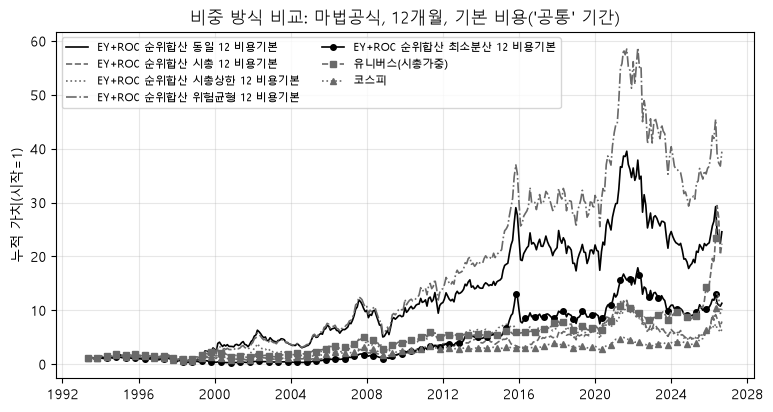

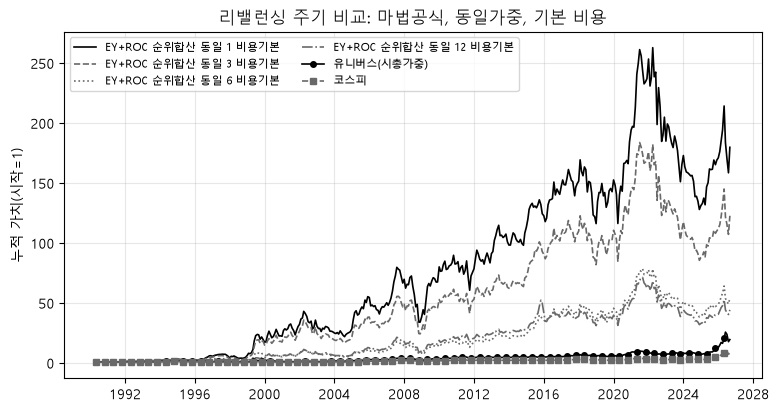

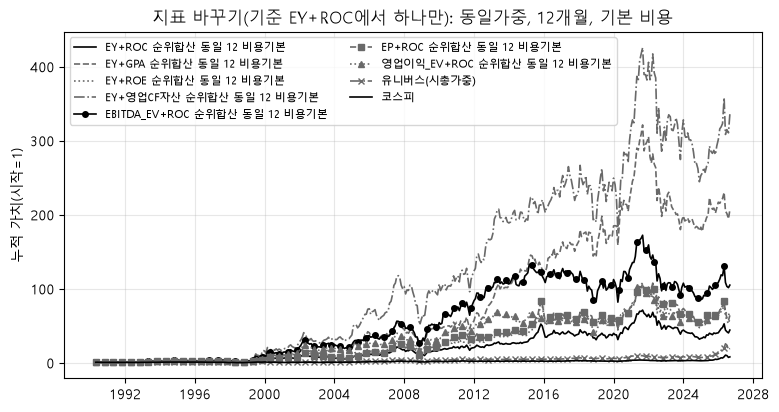

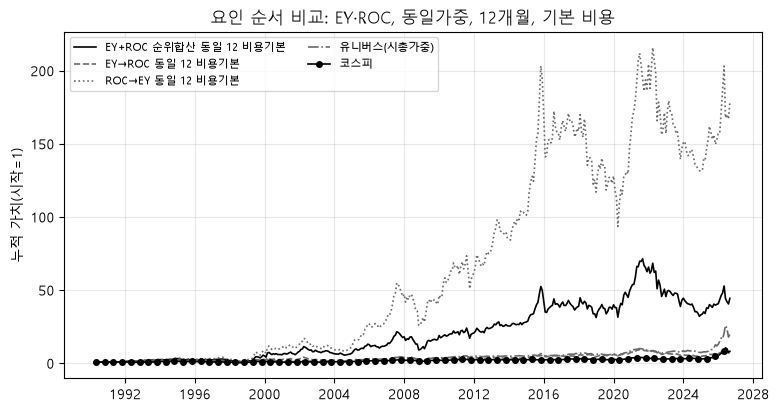

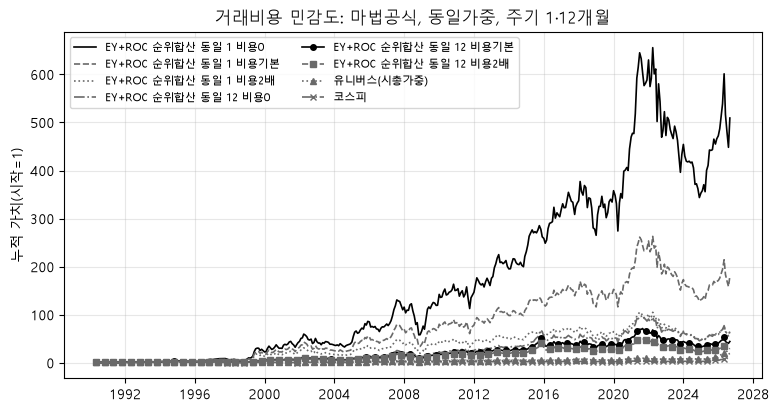

In [14]:
리포트 = Path.cwd().parent / "결과_전략수익률"
리포트.mkdir(exist_ok=True)
기준 = ("EY+ROC 순위합산", "동일", 12, "비용기본")
벤치줄 = lambda g: [("벤치:유니버스(시총가중)", "-", 0, "비용0", g), ("벤치:코스피", "-", 0, "비용0", g)]


def 비교(이름, 줄, 기간="전체", 그림열=None, 제목=""):
    """표 줄(전략, 비중, 주기, 비용) + 벤치마크 → csv, 그림열(수익 열) + 벤치마크 → 누적 png. 그 표를 돌려준다."""
    t = 표.reindex([(*k, 기간) for k in 줄] + 벤치줄(기간)).dropna(how="all")
    t.to_csv(리포트 / f"{이름}.csv", encoding="utf-8-sig")
    if 그림열:
        a = 공통 if 기간 == "공통" else None
        R = pd.concat([수익[k].rename(" ".join(map(str, k))) for k in 그림열] + [벤치[n] for n in ["유니버스(시총가중)", "코스피"]], axis=1)
        R = 평가.구간(R.loc[R[[" ".join(map(str, k)) for k in 그림열]].notna().any(axis=1).idxmax():], a, None)  # 첫 전략 수익률이 생긴 달부터
        평가.누적그림(R, 제목).savefig(리포트 / f"{이름}.png", dpi=150, bbox_inches="tight")
    return t


s0, b0, k0, c0 = 기준
비중들, 질들 = 설정["비중"], list(질)
t1 = 비교("1_비중", [(s0, b, k0, c0) for b in 비중들], "공통", [(s0, b, k0, c0) for b in 비중들], "비중 방식 비교: 마법공식, 12개월, 기본 비용('공통' 기간)")
t2 = 비교("2_주기", [(s0, b0, k, c0) for k in 주기들], "전체", [(s0, b0, k, c0) for k in 주기들], "리밸런싱 주기 비교: 마법공식, 동일가중, 기본 비용")
지표줄 = [(f"{v}+{q} 순위합산", b0, k0, c0) for v in 가치 for q in 질 if f"{v}+{q} 순위합산" in 전략들]
한개만 = [k for k in 지표줄 if k[0].startswith("EY+") or k[0].endswith("+ROC 순위합산")]
t3 = 비교("3_지표", 지표줄, "전체", 한개만, "지표 바꾸기(기준 EY+ROC에서 하나만): 동일가중, 12개월, 기본 비용")
순서줄 = [(n, b0, k0, c0) for n in ["EY+ROC 순위합산", "EY→ROC", "ROC→EY"]]
t4 = 비교("4_순서", 순서줄, "전체", 순서줄, "요인 순서 비교: EY·ROC, 동일가중, 12개월, 기본 비용")
비용줄 = [(s0, b0, k, c) for k in [1, 12] for c in 비용배수]
t5 = 비교("5_비용", 비용줄, "전체", 비용줄, "거래비용 민감도: 마법공식, 동일가중, 주기 1·12개월")
t6 = pd.concat({g: 표.reindex([(*기준, g)] + 벤치줄(g)).dropna(how="all") for g in list(평가.구간들)[1:]}, names=["기간칸"]).droplevel(-1)
t6.to_csv(리포트 / "6_기간.csv", encoding="utf-8-sig")
print("저장:", sorted(f.name for f in 리포트.iterdir()))
pd.concat({"1_비중": t1, "2_주기": t2, "4_순서": t4, "5_비용": t5}, names=["비교"])[["개월", "연환산", "표준편차(연)", "샤프", "MDD", "회전율(전 기간)", "벤치 대비 연환산", "정보비율", "Carhart α(월)", "Carhart t(NW)"]]

## 7. 확인: 리밸런싱마다 단계별 종목 수 (12개월 주기)

In [15]:
결과[12]["기록"].loc[:, ~결과[12]["기록"].columns.str.contains(":") | 결과[12]["기록"].columns.str.startswith(("빈칸:", "확인:"))].T

기준일,1990-04-02,1991-04-01,1992-04-01,1993-04-01,1994-04-01,1995-04-01,1996-04-01,1997-04-01,1998-04-01,1999-04-01,2000-04-03,2001-04-02,2002-04-01,2003-04-01,2004-04-01,2005-04-01,2006-04-03,2007-04-02,2008-04-01,2009-04-01,2010-04-01,2011-04-01,2012-04-02,2013-04-01,2014-04-01,2015-04-01,2016-04-01,2017-04-03,2018-04-02,2019-04-01,2020-04-01,2021-04-01,2022-04-01,2023-04-03,2024-04-01,2025-04-01,2026-04-01
가격있음,729,773,784,793,802,848,885,1270,1308,1239,1419,1511,1670,1738,1754,1756,1801,1872,1952,1981,1966,1970,1970,1929,1922,1953,2050,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
시장,729,773,784,793,802,848,885,1270,1308,1239,1419,1511,1670,1738,1754,1756,1801,1872,1952,1981,1966,1970,1970,1929,1922,1953,2050,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
쓰지말것,729,773,784,793,802,848,885,1270,1308,1230,1413,1507,1665,1734,1751,1752,1799,1870,1945,1976,1958,1965,1968,1923,1912,1953,2050,2101,2162,2237,2326,2419,2493,2577,2675,2754,2770
보통주,607,639,645,653,662,690,720,1081,1131,1047,1209,1308,1466,1548,1571,1581,1633,1706,1775,1806,1799,1812,1817,1776,1772,1826,1932,1983,2044,2121,2206,2298,2370,2454,2558,2638,2657
금융업,522,553,558,566,574,595,624,931,988,941,1099,1205,1375,1461,1488,1504,1558,1631,1699,1731,1718,1713,1725,1704,1706,1734,1805,1858,1854,1919,2029,2111,2180,2248,2338,2401,2435
투자기구,522,553,558,566,574,595,624,931,988,941,1099,1205,1374,1458,1482,1483,1523,1583,1656,1689,1679,1674,1684,1664,1677,1708,1781,1844,1844,1907,2018,2095,2160,2226,2315,2378,2414
결산월,433,462,468,478,488,508,536,816,871,822,906,1038,1232,1335,1370,1394,1442,1505,1567,1604,1601,1606,1626,1613,1631,1663,1741,1803,1807,1869,1975,2054,2121,2189,2279,2345,2384
거래정지,433,462,468,478,488,506,533,815,867,809,873,1006,1199,1305,1332,1344,1403,1476,1524,1506,1534,1569,1580,1568,1598,1632,1709,1767,1769,1810,1881,1952,2025,2128,2194,2259,2292
빈칸:EY,9,5,3,7,12,10,9,75,71,44,23,9,28,56,80,98,109,119,129,99,105,128,86,78,91,91,99,125,125,133,22,16,16,16,26,28,29
빈칸:ROC,86,90,91,81,86,84,87,245,247,209,185,192,225,276,297,305,307,309,323,300,302,318,108,92,112,112,124,148,148,152,42,35,34,41,48,52,53


## 8. 한계
- 지표 근거 중 '확인 안 함'인 것(영업이익_EV, 영업CF자산)은 원문 숫자와 비교하지 않았다.
- 남길 비율 50%, 시총상한 10%, 최소분산 36개월은 근거 없는 값이다.
- 거래비용은 전 기간 같은 값이다(거래세율의 연도별 변화는 넣지 않음).
- 여러 조합 중 가장 좋은 것을 고르면 과최적화(데이터 마이닝) 위험이 있다. 조합 전체의 분포(중앙값)와 기간별 일관성으로 본다.
- 그 밖의 데이터 한계는 README '한계·미해결'.